# Simulation and Analysis of Excitatory-Inhibitory Neuronal Networks (E-I Networks)

This example demonstrates the implementation of a classical excitatory-inhibitory (E-I) neuronal network using the `braincell` framework. By constructing an E-I network composed of Hodgkin-Huxley model neurons, you will learn how to implement hierarchical modeling from single neurons to networks in `braincell`, and analyze the spike dynamics of the network.

## Preparation
First, ensure that the necessary libraries (`braincell`, `brainstate`, `brainunit`, `matplotlib`) are installed, and import the required modules:


In [1]:
import brainpy
import braintools
import brainunit as u
import matplotlib.pyplot as plt
import brainstate
import braincell
from braincell import mech

## Code Explanation

### Parameter Definition

First, define the membrane area of each neuron:


In [2]:
# Neuron membrane area
area = 20000 * u.um ** 2

# A cylinder as long as it is wide, with that membrane area
diam = u.math.sqrt(area / u.math.pi)

### Define HH single neuron model

Use `braincell.Cell.point` to construct a population of point neurons based on the HH model, with the sodium channel `Na_TM1991`, the potassium channel `K_TM1991`, and the leak current `IL`. These channels jointly determine the firing properties of the neuron. Conductances are densities and the membrane capacitance is 1 µF/cm²; the cell scales them by its membrane area:

In [3]:
def HH(in_size):
    cell = braincell.Cell.point(
        in_size,
        length=diam,
        radius=diam / 2,
        V_init=braintools.init.Uniform(-70. * u.mV, -60. * u.mV),  # random initial voltage
        solver='ind_exp_euler',
    )
    cell.paint(
        # Sodium channel (INa)
        mech.Ion('SodiumFixed', E=50. * u.mV),
        mech.Channel('Na_TM1991', g_max=100. * u.mS * u.cm ** -2, V_sh=-63. * u.mV),

        # Potassium channel (IK)
        mech.Ion('PotassiumFixed', E=-90 * u.mV),
        mech.Channel('K_TM1991', g_max=30. * u.mS * u.cm ** -2, V_sh=-63. * u.mV),

        # Leak current (IL)
        # gl = 5e-5 S/cm^2 (Brette et al. 2007, benchmark 3; Brian2's examples/COBAHH.py)
        mech.Channel('IL', E=-60. * u.mV, g_max=0.05 * u.mS * u.cm ** -2),
    )
    return cell

### Define E-I Network: Connections Between Excitatory and Inhibitory Neurons

Construct a network composed of excitatory (E) and inhibitory (I) neurons to simulate the commonly observed E-I balance mechanism in cortical networks. The synaptic weights are total conductances (nS); the cell divides the synaptic current by its membrane area:


In [4]:
class EINet(brainstate.nn.Module):
    def __init__(self):
        super().__init__()
        # Network scale
        self.n_exc = 3200
        self.n_inh = 800
        self.num = self.n_exc + self.n_inh  # Total number of neurons: 4000

        # Initialize neuron population
        self.N = HH(self.num)

        # Excitatory synaptic projection
        self.E = brainpy.state.AlignPostProj(
            # Connection rule
            comm=brainstate.nn.EventFixedProb(
                self.n_exc, self.num, conn_num=0.02,  # Connection probability
                conn_weight=6. * u.nS  # Synaptic weight
            ),
            # Synaptic dynamics
            syn=brainpy.state.Expon(self.num, tau=5. * u.ms),
            # Postsynaptic effect
            out=brainpy.state.COBA(E=0. * u.mV),
            post=self.N  # Projection target is neuron population N
        )

        # Inhibitory synaptic projection
        self.I = brainpy.state.AlignPostProj(
            # Connection rule
            comm=brainstate.nn.EventFixedProb(
                self.n_inh, self.num, conn_num=0.02,
                conn_weight=67. * u.nS
            ),
            # Synaptic dynamics
            syn=brainpy.state.Expon(self.num, tau=10. * u.ms),
            # Postsynaptic effect
            out=brainpy.state.COBA(E=-80. * u.mV),
            post=self.N  # Projection target is neuron population N
        )

    def update(self, t):
        # Define network update rules over time
        with brainstate.environ.context(t=t):
            # Get spike signals at current time
            spk = self.N.spike.value

            # Spikes from excitatory neurons drive excitatory synaptic projection
            self.E(spk[:self.n_exc])

            # Spikes from inhibitory neurons drive inhibitory synaptic projection
            self.I(spk[self.n_exc:])

            # Neurons update their states after receiving synaptic inputs, return new spike signals
            spk = self.N(0. * u.nA)

            return spk


### Run network simulation

Initialize the network and run the simulation, recording the spike activity of neurons at each time point:


In [5]:
# Initialize E-I network
net = EINet()
brainstate.nn.init_all_states(net)  # Initialize the states of all neurons and synapses in the network

# Set simulation parameters and run
with brainstate.environ.context(dt=0.1 * u.ms):  # Time step
    # Generate simulation time sequence
    times = u.math.arange(0. * u.ms, 100. * u.ms, brainstate.environ.get_dt())

    # Loop to update network states
    spikes = brainstate.transform.for_loop(
        net.update, times,
        pbar=brainstate.transform.ProgressBar(10)  # Display progress bar
    )


  0%|          | 0/1000 [00:00<?, ?it/s]

### Visualize network spike activity

Plot the spike data as a raster plot to intuitively show the firing patterns of neurons over time:


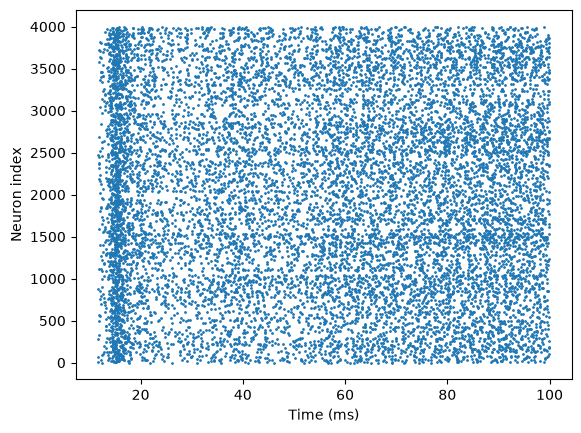

In [6]:
# Extract spike times and neuron indices
t_indices, n_indices = u.math.where(spikes)
# The spike of the step from t to t + dt is at t + dt, as `Cell.run` reports it
spike_times = times[t_indices] + (times[1] - times[0])

# Plot raster plot
plt.scatter(spike_times / u.ms, n_indices, s=1)
plt.xlabel('Time (ms)')  # X-axis: time
plt.ylabel('Neuron index')  # Y-axis: neuron index
plt.show()

## Results Interpretation

After running the code, you will see a raster plot, as shown below:

![raster plot](../_static/cobahh2007.png)

Each point represents a spike fired by a neuron at a specific time. Typical dynamics of an E-I network have the following characteristics:
- Asynchronous firing: Neurons fire at dispersed times without obvious synchronous rhythms.
- Sparse activity: Most neurons fire only a few times within 100 ms.
- No burst synchronization: Rapid feedback from inhibitory synapses prevents large-scale synchronous bursting.

These features indicate that the E-I network maintains a stable and physiologically realistic activity pattern through dynamic balance between excitatory and inhibitory neurons.

## Extended Exercises

- Adjust inhibitory synaptic weights and observe whether the network exhibits excessive synchronization or bursting activity.
- Increase the proportion of excitatory neurons to analyze the impact of E-I imbalance on network dynamics.
- Extend the simulation duration to see if the network maintains stable asynchronous activity.

Through these extensions, you can gain deeper insights into the critical role of E-I balance in maintaining neural network function, and the flexibility of `braincell` in modeling complex networks.
